In [1]:
import numpy as np

In [2]:
from astropy.units import u
from astropy.time import Time

In [3]:
import pickle

In [51]:
import h5py

In [30]:
from astropy.io import fits,ascii

In [34]:
overlaps0=ascii.read('window_overlaps.csv', delimiter=',')

In [36]:
dir(overlaps0)

['Column',
 'ColumnClass',
 'MaskedColumn',
 'Row',
 'TableColumns',
 'TableFormatter',
 '__array__',
 '__bytes__',
 '__class__',
 '__copy__',
 '__deepcopy__',
 '__delattr__',
 '__delitem__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__ior__',
 '__le__',
 '__len__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__or__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setitem__',
 '__setstate__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_base_repr_',
 '_check_names_dtype',
 '_column_class',
 '_convert_col_for_table',
 '_convert_data_to_col',
 '_convert_string_dtype',
 '_copy_indices',
 '_get_col_cls_for_table',
 '_init_from_cols',
 '_init_from_dict',
 '_init_from_list',
 '_init_from_list_of_dicts',
 '_init_from_ndarray',
 '_init_indices',
 '_ipython_

In [40]:
overlaps=overlaps0.as_array()

In [41]:
#read in dates and file locs
with open('dates_and_dirs.pkl', 'rb') as f:
    dates_and_dirs = pickle.load(f)

In [42]:
neid_date_sets=[]
expres_date_sets=[]
for item in overlaps:
    st=item[0]
    end=item[1]
    t_start=Time(st, format="jd")
    t_end=Time(end, format="jd")

    #find the dates and locations for observations that fall within this range
    #NEID
    neids=[]
    expreses=[]
    for date,floc in zip(dates_and_dirs['NEID_dates'], dates_and_dirs['NEID_file_locs']):
        t_date=Time(date, format="jd")      
        if (t_date >= t_start) & (t_date <= t_end):
            neids.append( (date, floc) )
    for date,floc in zip(dates_and_dirs['EXPRES_dates'], dates_and_dirs['EXPRES_file_locs']):
        t_date=Time(date, format="jd")      
        if (t_date >= t_start) & (t_date <= t_end):
            expreses.append( (date, floc) )
    neid_date_sets.append(neids)
    expres_date_sets.append(expreses)


In [44]:
#function to get flux, waves, and uncs from EXPRES
def read_expr_fits(hdul):
    flux = hdul[1].data['spectrum']
    wave = hdul[1].data['bary_wavelength']
    unc = hdul[1].data['uncertainty']
    return flux, wave, unc

In [45]:
#function to get flux, wavelengths, and uncertainties from NEID fits file
def read_neid_fits(hdul):
    flux=hdul['SCIFLUX'].data/hdul['SCIBLAZE'].data
    uncert=np.sqrt(hdul['SCIVAR'].data)/hdul['SCIBLAZE'].data
    wave=hdul['SCIWAVE'].data

    return wave, flux, uncert

In [46]:
def coadd_spectra(date_set, instrument):
    all_waves=[]
    all_fluxes=[]
    all_uncerts=[]

    exists_iscoadd=[False]*len(date_set)
    for i,date_set in enumerate(date_set):
        fluxes=[]
        uncerts=[]
        wave=[]
        for date, floc in date_set:
            with fits.open(floc) as hdul:
                if instrument=='NEID':
                    wave, flux, uncert=read_neid_fits(hdul)
                elif instrument=='EXPRES':
                    flux, wave, uncert=read_expr_fits(hdul)
                exists_iscoadd[i]=True
                fluxes.append(flux)
                uncerts.append(uncert)
        #coadd the fluxes, weighting by the uncertainties
        fluxes=np.array(fluxes)
        uncerts=np.array(uncerts)
        weights=1/(uncerts**2)
        weighted_fluxes=fluxes*weights
        coadd_flux=np.sum(weighted_fluxes, axis=0)/np.sum(weights, axis=0)
        #get the uncertainty on the coadded flux
        coadd_uncert=np.sqrt(1/np.sum(weights, axis=0))
        all_uncerts.append(coadd_uncert)

        all_fluxes.append(coadd_flux)
        all_waves.append(wave)

    return all_waves, all_fluxes, all_uncerts, exists_iscoadd

In [47]:
neid_wls,neid_coadds,neid_uncerts,neid_iscoadd=coadd_spectra(neid_date_sets, instrument='NEID')

/var/folders/xb/q0l5w32110b83grch639l1vm0000gn/T/ipykernel_88249/183926195.py:25: RuntimeWarning: invalid value encountered in scalar divide
  coadd_flux=np.sum(weighted_fluxes, axis=0)/np.sum(weights, axis=0)
/var/folders/xb/q0l5w32110b83grch639l1vm0000gn/T/ipykernel_88249/183926195.py:27: RuntimeWarning: divide by zero encountered in scalar divide
  coadd_uncert=np.sqrt(1/np.sum(weights, axis=0))
/var/folders/xb/q0l5w32110b83grch639l1vm0000gn/T/ipykernel_88249/3179065663.py:3: RuntimeWarning: invalid value encountered in divide
  flux=hdul['SCIFLUX'].data/hdul['SCIBLAZE'].data
/var/folders/xb/q0l5w32110b83grch639l1vm0000gn/T/ipykernel_88249/3179065663.py:4: RuntimeWarning: invalid value encountered in sqrt
  uncert=np.sqrt(hdul['SCIVAR'].data)/hdul['SCIBLAZE'].data


In [48]:
expres_wls,expres_coadds,expres_uncerts,expres_iscoadd=coadd_spectra(expres_date_sets, instrument='EXPRES')

/var/folders/xb/q0l5w32110b83grch639l1vm0000gn/T/ipykernel_88249/183926195.py:25: RuntimeWarning: invalid value encountered in scalar divide
  coadd_flux=np.sum(weighted_fluxes, axis=0)/np.sum(weights, axis=0)
/var/folders/xb/q0l5w32110b83grch639l1vm0000gn/T/ipykernel_88249/183926195.py:27: RuntimeWarning: divide by zero encountered in scalar divide
  coadd_uncert=np.sqrt(1/np.sum(weights, axis=0))


#for each item in date_sets, open the fits files at the flie location
#and extract the flux and uncertainties
#then coadd the files for each item, weighting by the uncertainties
neid_coadds=[]
neid_uncerts=[]
neid_wls=[]
neid_iscoadd=[False]*len(neid_date_sets)
for i,date_set in enumerate(neid_date_sets):
    fluxes=[]
    uncerts=[]
    wave=[]
    for date, floc in date_set:
        with fits.open(floc) as hdul:
            neid_iscoadd[i]=True
            flux=hdul['SCIFLUX'].data/hdul['SCIBLAZE'].data
            uncert=np.sqrt(hdul['SCIVAR'].data)/hdul['SCIBLAZE'].data
            fluxes.append(flux)
            uncerts.append(uncert)

            wave=hdul['SCIWAVE'].data
    #coadd the fluxes, weighting by the uncertainties
    fluxes=np.array(fluxes)
    uncerts=np.array(uncerts)
    weights=1/(uncerts**2)
    weighted_fluxes=fluxes*weights
    coadd_flux=np.sum(weighted_fluxes, axis=0)/np.sum(weights, axis=0)
    #get the uncertainty on the coadded flux
    coadd_uncert=np.sqrt(1/np.sum(weights, axis=0))
    neid_uncerts.append(coadd_uncert)

    neid_coadds.append(coadd_flux)
    neid_wls.append(wave)

In [49]:
#print the items in neid_coadds where there is data
for i, coadd in enumerate(neid_coadds):
    if neid_iscoadd[i]:
        print(f"Overlap {i}: Coadded NEID flux with shape {coadd.shape}")
        #print average % uncertainty for orders 20, 40, 60, and 80 for that data
        orders_to_check=[20,40,60,80]
        for order in orders_to_check:
            avg_uncert=np.nanmean(neid_uncerts[i][order]/neid_coadds[i][order])*100
            print(f"  Order {order}: Average % uncertainty: {avg_uncert:.2f}%")

Overlap 76: Coadded NEID flux with shape (122, 9216)
  Order 20: Average % uncertainty: 0.36%
  Order 40: Average % uncertainty: 0.07%
  Order 60: Average % uncertainty: 0.03%
  Order 80: Average % uncertainty: 0.02%
Overlap 77: Coadded NEID flux with shape (122, 9216)
  Order 20: Average % uncertainty: 0.48%
  Order 40: Average % uncertainty: 0.09%
  Order 60: Average % uncertainty: 0.04%
  Order 80: Average % uncertainty: 0.03%


In [27]:
#print the items in neid_coadds where there is data
for i, coadd in enumerate(expres_coadds):
    if expres_iscoadd[i]:
        print(f"Overlap {i}: Coadded EXPRES flux with shape {coadd.shape}")
        #print average % uncertainty for orders 20, 40, 60, and 80 for that data
        orders_to_check=[20,40,60,80]
        for order in orders_to_check:
            avg_uncert=np.nanmean(expres_uncerts[i][order]/expres_coadds[i][order])*100
            print(f"  Order {order}: Average % uncertainty: {avg_uncert:.2f}%")

Overlap 76: Coadded EXPRES flux with shape (86, 7920)
  Order 20: Average % uncertainty: 0.22%
  Order 40: Average % uncertainty: 0.06%
  Order 60: Average % uncertainty: 0.04%
  Order 80: Average % uncertainty: 0.35%
Overlap 77: Coadded EXPRES flux with shape (86, 7920)
  Order 20: Average % uncertainty: 0.31%
  Order 40: Average % uncertainty: 0.09%
  Order 60: Average % uncertainty: 0.05%
  Order 80: Average % uncertainty: 0.43%


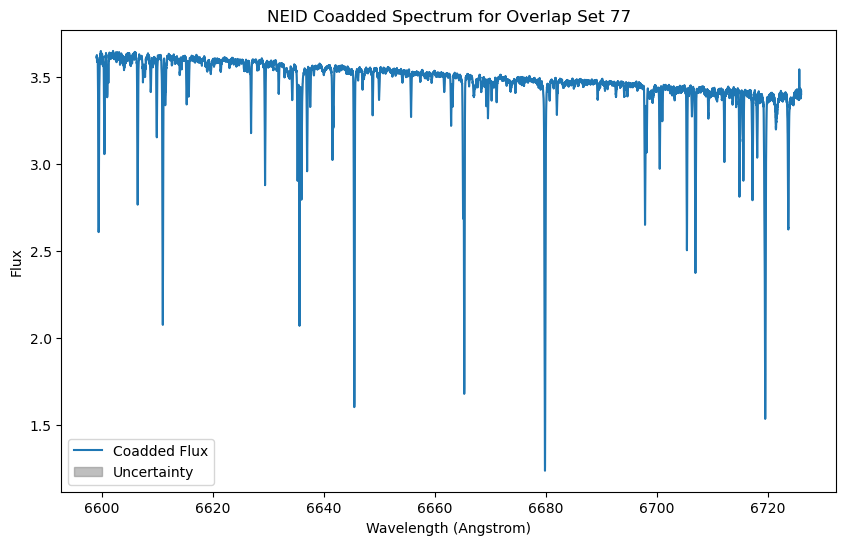

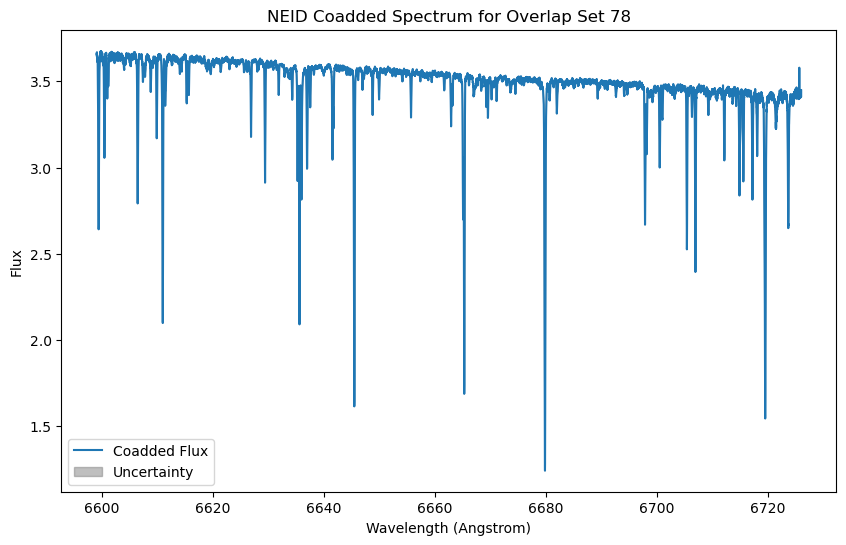

In [50]:
#for the items in neid_coadds with data, plot the coadded fluxes with uncertainties as a function of wavelength
import matplotlib.pyplot as plt

o=81

for i in range(len(neid_coadds)):
    if neid_iscoadd[i]:
        plt.figure(figsize=(10,6))
        plt.plot(neid_wls[i][o], neid_coadds[i][o], label='Coadded Flux')
        #use plt errorbar to plot uncertainties
        #plt.errorbar(neid_wls[i][o], neid_coadds[i][o], yerr=neid_uncerts[i][o], fmt='none', ecolor='gray', alpha=0.5, capsize=2)
        plt.fill_between(neid_wls[i][o], neid_coadds[i][o]-neid_uncerts[i][o], neid_coadds[i][o]+neid_uncerts[i][o], color='gray', alpha=0.5, label='Uncertainty')
        plt.xlabel('Wavelength (Angstrom)')
        plt.ylabel('Flux')
        plt.title(f'NEID Coadded Spectrum for Overlap Set {i+1}')
        #plt.xlim(5820,5840)
        plt.legend()
        plt.show()

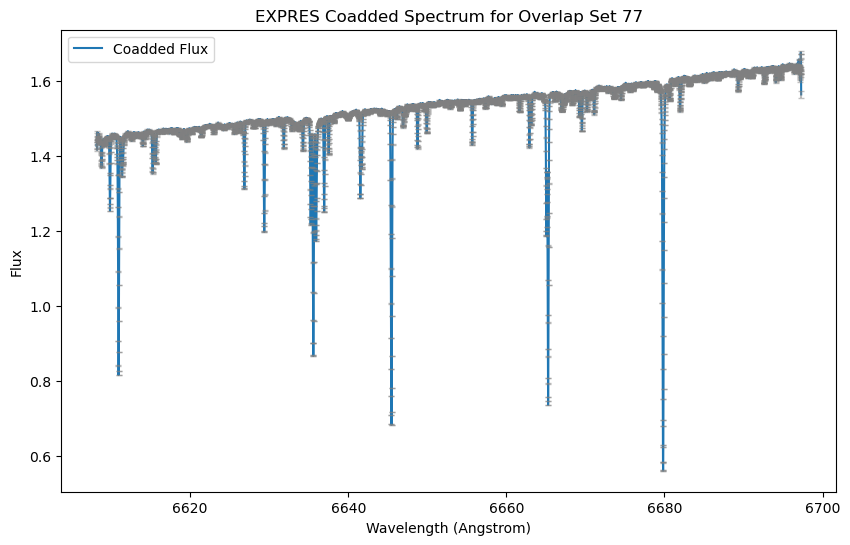

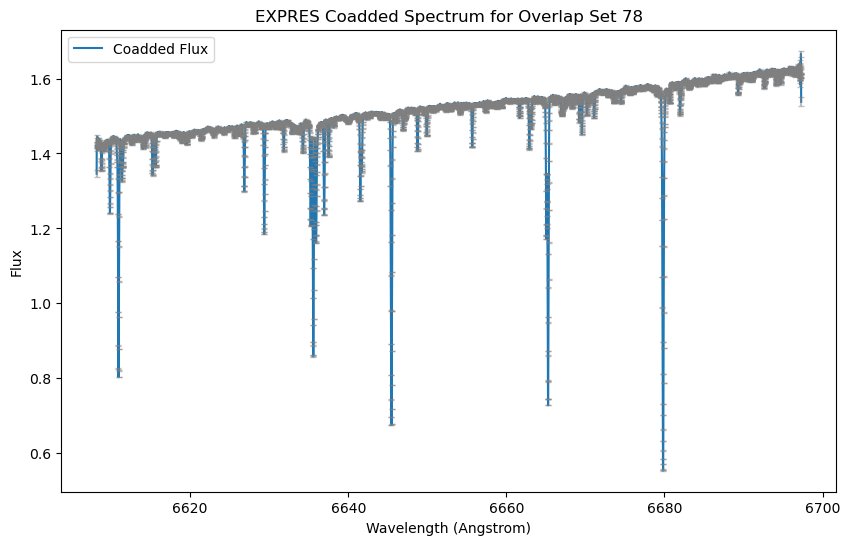

In [20]:


o=68

for i in range(len(expres_coadds)):
    if expres_iscoadd[i]:
        plt.figure(figsize=(10,6))
        plt.plot(expres_wls[i][o], expres_coadds[i][o], label='Coadded Flux')
        #use plt errorbar to plot uncertainties
        plt.errorbar(expres_wls[i][o], expres_coadds[i][o], yerr=expres_uncerts[i][o], fmt='none', ecolor='gray', alpha=0.5, capsize=2)
        #plt.fill_between(expres_wls[i], expres_coadds[i]-expres_uncerts[i], expres_coadds[i]+expres_uncerts[i], color='gray', alpha=0.5, label='Uncertainty')
        plt.xlabel('Wavelength (Angstrom)')
        plt.ylabel('Flux')
        plt.title(f'EXPRES Coadded Spectrum for Overlap Set {i+1}')
        #plt.xlim(5820,5840)
        plt.legend()
        plt.show()

In [52]:
#save output to h5 file
with h5py.File('coadded_spectra.h5', 'w') as hf:
    hf.create_dataset('neid_wls', data=neid_wls)
    hf.create_dataset('neid_coadds', data=neid_coadds)
    hf.create_dataset('neid_uncerts', data=neid_uncerts)
    hf.create_dataset('expres_wls', data=expres_wls)
    hf.create_dataset('expres_coadds', data=expres_coadds)
    hf.create_dataset('expres_uncerts', data=expres_uncerts)
    hf.create_dataset('neid_iscoadd', data=neid_iscoadd)
    hf.create_dataset('expres_iscoadd', data=expres_iscoadd)
    hf.create_dataset('neid_date_sets', data=neid_date_sets)
    hf.create_dataset('expres_date_sets', data=expres_date_sets)


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (363,) + inhomogeneous part.